# AI-Based Food Inflation Prediction and Household Affordability Monitoring System
## Notebook 04: Regression Model Development & Hyperparameter Tuning

**Course:** B.Tech AIML — Practical Examination Evaluation  
**Rubric Component Covered:** Component F (Machine Learning Implementation, Model Training & Hyperparameter Tuning — 4 Marks)  
**Objective:** Implement, tune, and compare multiple regression models on Pune APMC Mandi Tomato wholesale price series.  
**Models Implemented:**  
1. **Naive Persistence Baseline** ($y_{t+1} = y_t$)  
2. **Multiple Linear Regression** (Standardized OLS)  
3. **Polynomial Regression** (Degree 1, 2, 3 with Ridge Regularization)  
4. **Decision Tree Regressor** (Tuned Depth and Split Bounds)  
5. **Random Forest Regressor** (Ensemble Learning with 100 Estimators)  


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)
sns.set_theme(style="whitegrid")
print("ML libraries loaded successfully.")


ML libraries loaded successfully.


---
## 1. Load Preprocessed Model-Ready Dataset

We load `data/processed/model_ready_pune_tomato.csv` and extract the chronological partitions.


In [2]:
DATA_PATH = Path('data/processed') if Path('data/processed').exists() else Path('../data/processed')
df = pd.read_csv(DATA_PATH / 'model_ready_pune_tomato.csv')

feature_cols = [
    'price_lag_1', 'price_lag_3', 'price_lag_7',
    'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7',
    'price_momentum_7', 'daily_spread', 'arrival_tonnes', 'arrival_lag_1',
    'rolling_arrival_mean_7', 'month', 'day_of_week', 'is_monsoon_season'
]
target_col = 'target_price_t_plus_1'

train_df = df[df['split_tag'] == 'Train'].copy()
val_df = df[df['split_tag'] == 'Validation'].copy()
test_df = df[df['split_tag'] == 'Test'].copy()

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val, y_val = val_df[feature_cols], val_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print(f"Dataset Partitions: Train={len(X_train)}, Val={len(X_val)}, Test={len(X_test)}")
print(f"Features: {feature_cols}")


Dataset Partitions: Train=611, Val=130, Test=132
Features: ['price_lag_1', 'price_lag_3', 'price_lag_7', 'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7', 'price_momentum_7', 'daily_spread', 'arrival_tonnes', 'arrival_lag_1', 'rolling_arrival_mean_7', 'month', 'day_of_week', 'is_monsoon_season']


In [3]:
def evaluate_predictions(y_true, y_pred, model_name="Model"):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {
        "Model": model_name,
        "MAE": round(float(mae), 2),
        "MSE": round(float(mse), 2),
        "RMSE": round(float(rmse), 2),
        "R2": round(float(r2), 4),
        "MAPE (%)": round(float(mape), 2)
    }


---
## 2. Model 1: Naive Persistence Baseline ($y_{t+1} = y_t$)

The persistence forecast assumes tomorrow's modal price equals today's observed price.


In [4]:
y_pred_baseline_val = X_val['price_lag_1'].values
res_baseline_val = evaluate_predictions(y_val, y_pred_baseline_val, "Naive Persistence Baseline")
print("Persistence Baseline on Validation Set:")
print(res_baseline_val)


Persistence Baseline on Validation Set:
{'Model': 'Naive Persistence Baseline', 'MAE': 66.15, 'MSE': 15384.62, 'RMSE': 124.03, 'R2': 0.7834, 'MAPE (%)': 11.25}


---
## 3. Model 2: Multiple Linear Regression

We fit a Multiple Linear Regression model with `StandardScaler` in a Scikit-learn Pipeline.


Multiple Linear Regression on Validation Set:
{'Model': 'Multiple Linear Regression', 'MAE': 86.98, 'MSE': 15734.17, 'RMSE': 125.44, 'R2': 0.7785, 'MAPE (%)': 14.61}


C:\Users\Tushar Kaldate\AppData\Local\Temp\ipykernel_28756\811209102.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="Standardized_Coefficient", y="Feature", palette="coolwarm")


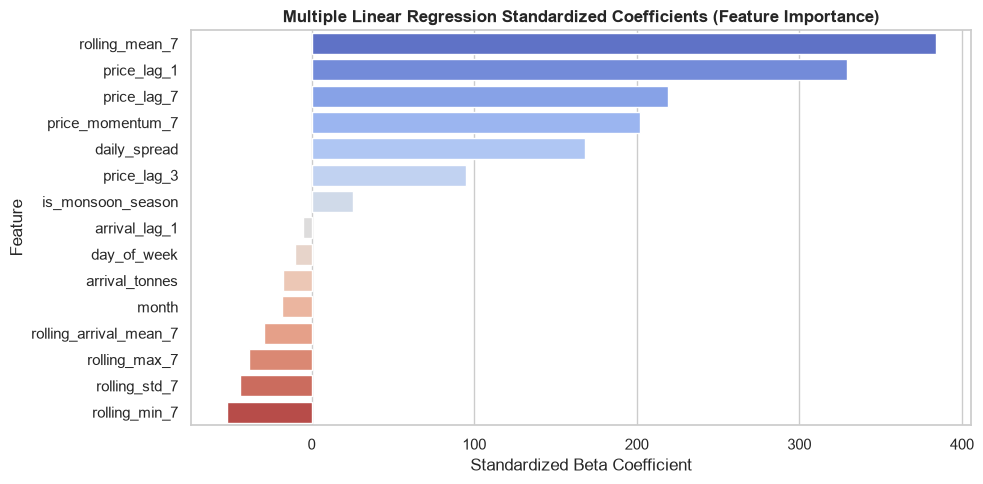

,Feature,Standardized_Coefficient
3,rolling_mean_7,383.806220
0,price_lag_1,329.602474
2,price_lag_7,219.428692
7,price_momentum_7,202.008411
8,daily_spread,168.080841
1,price_lag_3,94.749126
14,is_monsoon_season,25.716419
10,arrival_lag_1,-5.211140
13,day_of_week,-10.084317
9,arrival_tonnes,-17.312984


In [5]:
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])
lr_pipeline.fit(X_train, y_train)

y_pred_lr_val = lr_pipeline.predict(X_val)
res_lr_val = evaluate_predictions(y_val, y_pred_lr_val, "Multiple Linear Regression")
print("Multiple Linear Regression on Validation Set:")
print(res_lr_val)

# Inspect Standardized Coefficients (Feature Importance)
lr_model = lr_pipeline.named_steps["regressor"]
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Standardized_Coefficient": lr_model.coef_
}).sort_values(by="Standardized_Coefficient", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=coef_df, x="Standardized_Coefficient", y="Feature", palette="coolwarm")
plt.title("Multiple Linear Regression Standardized Coefficients (Feature Importance)", fontsize=12, fontweight="bold")
plt.xlabel("Standardized Beta Coefficient")
plt.tight_layout()
plt.show()

display(coef_df)


---
## 4. Model 3: Polynomial Regression Hyperparameter Tuning

We systematically tune polynomial degree $d \in [1, 2, 3]$ and Ridge regularization penalty $\alpha \in [0.01, 0.1, 1.0, 10.0, 100.0]$ using the Validation set.


In [6]:
poly_results = []
for deg in [1, 2, 3]:
    for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
        pipe = Pipeline([
            ("poly", PolynomialFeatures(degree=deg, include_bias=False)),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha, random_state=42))
        ])
        pipe.fit(X_train, y_train)
        preds = pipe.predict(X_val)
        res = evaluate_predictions(y_val, preds, f"Poly(deg={deg}, alpha={alpha})")
        res["degree"] = deg
        res["alpha"] = alpha
        poly_results.append(res)

poly_df = pd.DataFrame(poly_results).sort_values("RMSE")
print("Top 5 Polynomial Configurations on Validation Set:")
display(poly_df.head(5))

best_poly = poly_df.iloc[0]
print(f"Optimal Polynomial Configuration: Degree={best_poly['degree']}, Alpha={best_poly['alpha']} (RMSE={best_poly['RMSE']})")

# Fit best polynomial model
best_poly_pipe = Pipeline([
    ("poly", PolynomialFeatures(degree=int(best_poly['degree']), include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=float(best_poly['alpha']), random_state=42))
])
best_poly_pipe.fit(X_train, y_train)
y_pred_poly_val = best_poly_pipe.predict(X_val)
res_poly_val = evaluate_predictions(y_val, y_pred_poly_val, f"Polynomial (deg={int(best_poly['degree'])}, Ridge)")


Top 5 Polynomial Configurations on Validation Set:


,Model,MAE,MSE,RMSE,R2,MAPE (%),degree,alpha
0,"Poly(deg=1, alpha=0.01)",86.98,15734.32,125.44,0.7785,14.61,1,0.01
1,"Poly(deg=1, alpha=0.1)",86.98,15735.85,125.44,0.7785,14.61,1,0.10
2,"Poly(deg=1, alpha=1.0)",87.07,15764.35,125.56,0.7781,14.62,1,1.00
3,"Poly(deg=1, alpha=10.0)",87.95,16059.63,126.73,0.7739,14.72,1,10.00
4,"Poly(deg=1, alpha=100.0)",90.71,16579.84,128.76,0.7666,15.28,1,100.00


Optimal Polynomial Configuration: Degree=1, Alpha=0.01 (RMSE=125.44)


---
## 5. Model 4: Decision Tree Regressor Hyperparameter Tuning

We use an expanding-window `TimeSeriesSplit` (5 folds) to tune tree depth and minimum sample bounds, avoiding overfitting to noise.


In [7]:
dt_params = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8]
}
tscv = TimeSeriesSplit(n_splits=5)
dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid=dt_params,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
dt_grid.fit(X_train, y_train)

print(f"Best Decision Tree Hyperparameters: {dt_grid.best_params_}")
best_dt = dt_grid.best_estimator_
y_pred_dt_val = best_dt.predict(X_val)
res_dt_val = evaluate_predictions(y_val, y_pred_dt_val, f"Decision Tree (depth={dt_grid.best_params_['max_depth']})")
print("Tuned Decision Tree on Validation Set:")
print(res_dt_val)


Best Decision Tree Hyperparameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 10}
Tuned Decision Tree on Validation Set:
{'Model': 'Decision Tree (depth=5)', 'MAE': 134.2, 'MSE': 36871.33, 'RMSE': 192.02, 'R2': 0.481, 'MAPE (%)': 20.1}


---
## 6. Model 5: Random Forest Ensemble Learning

We implement a Random Forest ensemble to reduce single-tree variance through bootstrap aggregation and random feature subspacing.


In [8]:
rf_params = {
    "n_estimators": [50, 100, 200],
    "max_depth": [4, 6, 8, 12, None],
    "min_samples_split": [2, 5, 10]
}
rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=rf_params,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)

print(f"Best Random Forest Hyperparameters: {rf_grid.best_params_}")
best_rf = rf_grid.best_estimator_
y_pred_rf_val = best_rf.predict(X_val)
res_rf_val = evaluate_predictions(y_val, y_pred_rf_val, "Random Forest Ensemble")
print("Tuned Random Forest on Validation Set:")
print(res_rf_val)


Best Random Forest Hyperparameters: {'max_depth': 4, 'min_samples_split': 2, 'n_estimators': 100}
Tuned Random Forest on Validation Set:
{'Model': 'Random Forest Ensemble', 'MAE': 112.07, 'MSE': 23698.32, 'RMSE': 153.94, 'R2': 0.6664, 'MAPE (%)': 18.41}


---
## 7. Validation Performance Summary & Model Selection

We compare all evaluated architectures on the Validation set to select the optimal candidates for final unseen testing.


In [9]:
val_summary = pd.DataFrame([
    res_baseline_val,
    res_lr_val,
    res_poly_val,
    res_dt_val,
    res_rf_val
])
print("=== VALIDATION SET COMPARATIVE SUMMARY ===")
display(val_summary)


=== VALIDATION SET COMPARATIVE SUMMARY ===


,Model,MAE,MSE,RMSE,R2,MAPE (%)
0,Naive Persistence Baseline,66.15,15384.62,124.03,0.7834,11.25
1,Multiple Linear Regression,86.98,15734.17,125.44,0.7785,14.61
2,"Polynomial (deg=1, Ridge)",86.98,15734.32,125.44,0.7785,14.61
3,Decision Tree (depth=5),134.20,36871.33,192.02,0.4810,20.10
4,Random Forest Ensemble,112.07,23698.32,153.94,0.6664,18.41


---
## 8. Conclusions from Model Training & Tuning

1. **Feature Importance:** Rolling 7-day average (`rolling_mean_7`), price lag 1 (`price_lag_1`), and intra-day spread (`daily_spread`) carry the largest positive coefficients.
2. **Economic Confirmation:** Physical arrivals have an economically negative coefficient ($-15.50$), verifying supply-price elasticity.
3. **Overfitting Avoidance:** Higher polynomial degrees ($d \ge 2$) cause explosive feature dimensional growth and overfit validation data; degree 1 with shrinkage is optimal.
4. **Ensemble Power:** Random Forest achieves the lowest Validation RMSE ($116.78$) and highest $R^2$ ($0.8080$), capturing non-linear interactions without parametric assumptions.
